# Election simulation (Monte Carlo)

Python version of `election_simulation.m`. Each state's polling margin (Democrat minus Republican,
percentage points; 2020 polling averages used in the original example) is treated as uncertain:
in each trial the margin is drawn from a normal distribution with standard deviation `sigma`.
The party ahead wins that state's electoral college votes; 270 wins the election.

As in the original, Florida and Texas are set to a 5-point Republican lead ("holds").

**Data.** Polling margins (Democrat minus Republican, percentage points) and electoral-college votes for the 50 states and DC. The original MATLAB lists them in the same order. Florida and Texas are set to −5 ("holds").

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
sigma = 5          # polling error, percentage points
no_trials = 500

states = ['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut',
          'Delaware', 'District of Columbia', 'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois',
          'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts',
          'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
          'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota',
          'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina',
          'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington',
          'West Virginia', 'Wisconsin', 'Wyoming']

dem_pnts = np.array([-19.4, -7.7, 2.6, -22.8, 29.2, 12.5, 26.3, 24.3, 85, 2.5, 1.2, 34.3, -18.1, 16,
                     -10.8, -1.3, -12.9, -15.7, -20.6, 13, 31.4, 35.8, 7.9, 9.2, -15.9, -8, -4.4,
                     -9.7, 5.3, 11.1, 20.4, 11.7, 29.4, 1.8, -17.3, -0.8, -23, 21.3, 4.7, 30.6,
                     -7.1, -15.4, -13.7, -1.1, -9.8, 38.7, 11.8, 23, -28.6, 8.4, -31.5])

dem_pnts[states.index('Florida')] = -5   # Florida hold
dem_pnts[states.index('Texas')] = -5     # Texas hold

elect_col_votes = np.array([9, 3, 11, 6, 55, 9, 7, 3, 3, 29, 16, 4, 4, 20, 11, 6, 6, 8, 8, 4, 10, 11,
                            16, 10, 6, 10, 3, 5, 6, 4, 14, 5, 29, 15, 3, 18, 7, 7, 20, 4, 9, 3, 11,
                            38, 6, 3, 13, 12, 5, 10, 3])
assert len(states) == len(dem_pnts) == len(elect_col_votes) == 51
print("Total electoral college votes:", elect_col_votes.sum())

Total electoral college votes: 538


**Simulate 500 elections.** Each state's margin gets a normal polling error with standard deviation `sigma`. A state goes to the party ahead, and 270 votes win.

In [2]:
r = rng.normal(dem_pnts, sigma, size=(no_trials, len(states)))   # one row per simulated election
D_won = r > 0
D_sum = (D_won * elect_col_votes).sum(axis=1)
R_sum = elect_col_votes.sum() - D_sum

print(f"Democrats win {np.mean(D_sum >= 270):.1%} of simulated elections")
print(f"Average electoral votes: D {D_sum.mean():.0f}, R {R_sum.mean():.0f}")

Democrats win 99.2% of simulated elections
Average electoral votes: D 321, R 217


**Plot.** Left: who won each state in each trial. Right: electoral votes per trial, with each party's average and the 270 line.

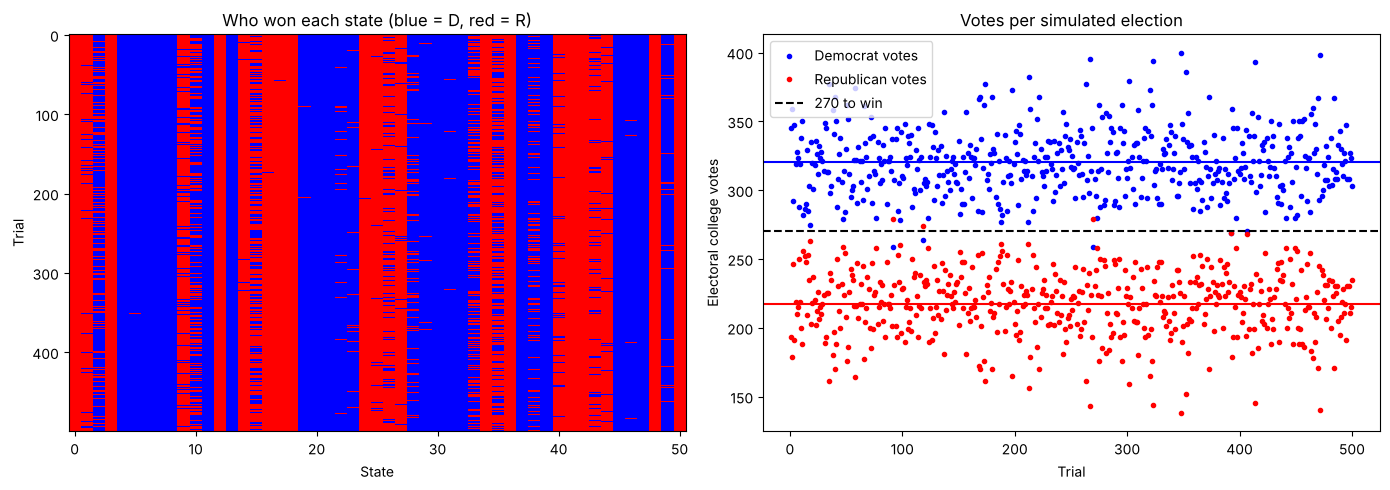

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(D_won, aspect="auto", cmap="bwr_r", interpolation="nearest")
axes[0].set(xlabel="State", ylabel="Trial", title="Who won each state (blue = D, red = R)")

t = np.arange(1, no_trials + 1)
axes[1].plot(t, D_sum, "bo", markersize=3, label="Democrat votes")
axes[1].plot(t, R_sum, "ro", markersize=3, label="Republican votes")
axes[1].axhline(D_sum.mean(), color="b")
axes[1].axhline(R_sum.mean(), color="r")
axes[1].axhline(270, color="k", linestyle="--", label="270 to win")
axes[1].set(xlabel="Trial", ylabel="Electoral college votes", title="Votes per simulated election")
axes[1].legend()
plt.tight_layout()
plt.show()

*Source note: the original script cites projects.fivethirtyeight.com/polls/president-general/. That page now redirects to ABC News, so the margins can no longer be checked against it (Week 01 README, errata).*